# Лабораторная работа № 2
## Разработка сверточной нейронной сети с использованием PyTorch


In [1]:
from google.colab import drive

drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


## 1. Импорт библиотек


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

import tarfile
import os
import pickle

from torch.utils.data import DataLoader, Dataset
from torchvision import transforms


## 2. Загрузка и предобработка данных

Используется набор данных CIFAR-10. Он содержит 60 000 цветных изображений размером 32×32 пикселя, относящихся к 10 классам: 50 000 изображений в обучающей выборке и 10 000 — в тестовой.

In [3]:
archive_path = '/content/drive/MyDrive/Datasets/cifar-10-python.tar.gz'
extract_path = '/content/data'
os.makedirs(extract_path, exist_ok=True)

with tarfile.open(archive_path, 'r:gz') as tar:
    tar.extractall(path=extract_path)

print("Архив успешно распакован!")
print(os.listdir(extract_path))
DATA_DIR = '/content/data/cifar-10-batches-py'

print(os.listdir(DATA_DIR))

/tmp/ipykernel_59019/3061597749.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Архив успешно распакован!
['cifar-10-batches-py']
['readme.html', 'data_batch_2', 'data_batch_5', 'data_batch_4', 'data_batch_1', 'batches.meta', 'test_batch', 'data_batch_3']


In [5]:
class CIFAR10Dataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx]

        image = image * 0.5 + 0.5

        if self.transform:
            image = self.transform(image)

        image = (image - 0.5) / 0.5

        return image, label

Для повышения обобщающей способности модели применяется аугментация обучающих изображений. Используются случайное кадрирование (`RandomCrop`), горизонтальное отражение (`RandomHorizontalFlip`), а также небольшие изменения яркости, контраста и насыщенности (`ColorJitter`). Эти преобразования позволяют получать различные варианты исходных изображений и помогают модели лучше распознавать объекты.

In [7]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    )
])

In [8]:
BATCH_SIZE = 64

def unpickle(file):
    with open(file, 'rb') as fo:
        data = pickle.load(fo, encoding='bytes')
    return data

X_train = []
y_train = []

for i in range(1, 6):
    batch = unpickle(os.path.join(DATA_DIR, f'data_batch_{i}'))

    X_train.append(batch[b'data'])
    y_train.extend(batch[b'labels'])

X_train = np.concatenate(X_train, axis=0)
y_train = np.array(y_train)

test_batch = unpickle(os.path.join(DATA_DIR, 'test_batch'))

X_test = test_batch[b'data']
y_test = np.array(test_batch[b'labels'])

X_train = X_train.reshape(-1, 3, 32, 32)
X_test = X_test.reshape(-1, 3, 32, 32)

X_train = torch.tensor(X_train, dtype=torch.float32) / 255.0
X_test = torch.tensor(X_test, dtype=torch.float32) / 255.0

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

X_train = (X_train - 0.5) / 0.5
X_test = (X_test - 0.5) / 0.5

trainset = CIFAR10Dataset(
    X_train,
    y_train,
    transform=train_transform
)

testset = CIFAR10Dataset(
    X_test,
    y_test,
    transform=None
)

trainloader = DataLoader(
    trainset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

testloader = DataLoader(
    testset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

meta = unpickle(os.path.join(DATA_DIR, 'batches.meta'))
classes = [
    name.decode('utf-8') for name in meta[b'label_names']
]

print("Классы:", classes)
print("Количество обучающих изображений:", len(trainset))
print("Количество тестовых изображений:", len(testset))


Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Количество обучающих изображений: 50000
Количество тестовых изображений: 10000


## 3. Размерности данных

Выведем количество примеров в каждой выборке, форму одного изображения и форму меток. Для CIFAR-10 ожидается, что изображение представлено тензором с тремя цветовыми каналами и пространственным размером 32×32.

In [9]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Диапазон значений:", X_train.min().item(), X_train.max().item())

X_train: torch.Size([50000, 3, 32, 32])
X_test: torch.Size([10000, 3, 32, 32])
y_train: torch.Size([50000])
y_test: torch.Size([10000])
Диапазон значений: -1.0 1.0


## 4. Просмотр примеров изображений

Отобразим несколько изображений обучающей выборки с соответствующими метками классов. Перед отображением выполним обратную нормализацию, чтобы восстановить привычный диапазон значений пикселей.

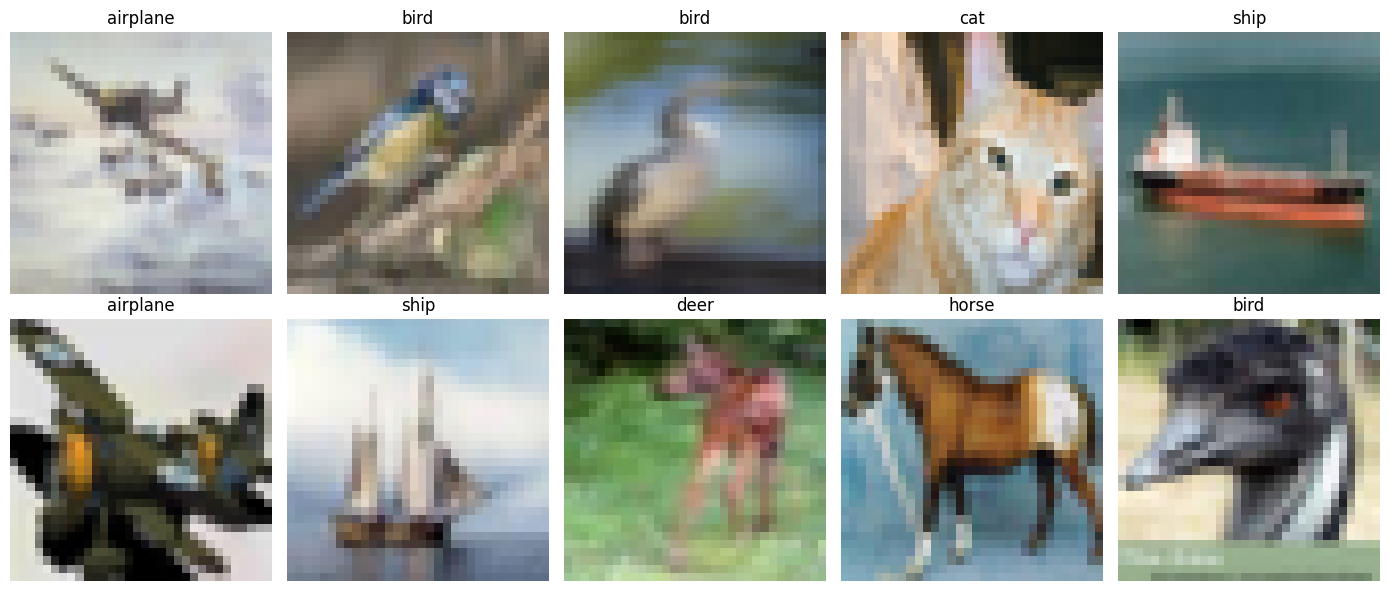

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Случайно выбираем 10 разных изображений
indices = np.random.choice(len(X_train), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flat):
    idx = indices[i]

    image = X_train[idx] * 0.5 + 0.5
    image = image.permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(classes[y_train[idx].item()])
    ax.axis('off')

plt.tight_layout()
plt.show()

## 5. Реализация сверточной нейронной сети

Реализуем собственную архитектуру `SimpleCNN` на базовых слоях PyTorch. Сеть состоит из трёх сверточных блоков, включающих свёртку, функцию активации ReLU и подвыборку MaxPooling, а также полносвязного классификатора.

Для входного изображения размером 3×32×32 после трёх операций MaxPooling размер карты признаков становится 4×4. Поэтому на вход первого полносвязного слоя поступает `256 × 4 × 4` признаков. Выходной слой содержит 10 нейронов — по одному на каждый класс CIFAR-10.

In [23]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


## 6. Настройка обучения

Для многоклассовой классификации используется функция потерь `CrossEntropyLoss`. В качестве оптимизатора выбран SGD с Momentum.

In [15]:
NUM_EPOCHS = 50
LEARNING_RATE = 0.01
MOMENTUM = 0.9
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM
)
scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=10,
    gamma=0.5
)

## 7. Обучение нейронной сети

На каждой эпохе модель обучается на всей тренировочной выборке. После завершения эпохи выводятся средняя ошибка классификации (`Loss`) и точность (`Accuracy`) на обучающем наборе.

Ошибка усредняется по количеству изображений, поэтому неполный последний батч учитывается корректно.

In [16]:
def train_model(model, trainloader, criterion, optimizer, device, num_epochs):
    train_losses = []
    train_accuracies = []

    for epoch in range(num_epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in trainloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += batch_size

        epoch_loss = running_loss / total
        epoch_accuracy = correct / total

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        scheduler.step()

        print(
            f"Эпоха [{epoch + 1}/{num_epochs}] "
            f"Train Loss: {epoch_loss:.4f}, "
            f"Train Accuracy: {epoch_accuracy:.4f}"
        )

    return train_losses, train_accuracies


train_losses, train_accuracies = train_model(
    model,
    trainloader,
    criterion,
    optimizer,
    device,
    NUM_EPOCHS
)

Эпоха [1/50] Train Loss: 1.4531, Train Accuracy: 0.4684
Эпоха [2/50] Train Loss: 1.1006, Train Accuracy: 0.6112
Эпоха [3/50] Train Loss: 0.9480, Train Accuracy: 0.6664
Эпоха [4/50] Train Loss: 0.8525, Train Accuracy: 0.7029
Эпоха [5/50] Train Loss: 0.7768, Train Accuracy: 0.7288
Эпоха [6/50] Train Loss: 0.7232, Train Accuracy: 0.7464
Эпоха [7/50] Train Loss: 0.6654, Train Accuracy: 0.7692
Эпоха [8/50] Train Loss: 0.6285, Train Accuracy: 0.7814
Эпоха [9/50] Train Loss: 0.5917, Train Accuracy: 0.7927
Эпоха [10/50] Train Loss: 0.5580, Train Accuracy: 0.8059
Эпоха [11/50] Train Loss: 0.4731, Train Accuracy: 0.8357
Эпоха [12/50] Train Loss: 0.4488, Train Accuracy: 0.8431
Эпоха [13/50] Train Loss: 0.4346, Train Accuracy: 0.8495
Эпоха [14/50] Train Loss: 0.4199, Train Accuracy: 0.8537
Эпоха [15/50] Train Loss: 0.4083, Train Accuracy: 0.8584
Эпоха [16/50] Train Loss: 0.3959, Train Accuracy: 0.8621
Эпоха [17/50] Train Loss: 0.3840, Train Accuracy: 0.8657
Эпоха [18/50] Train Loss: 0.3783, Train 

## 8. График изменения ошибки в процессе обучения


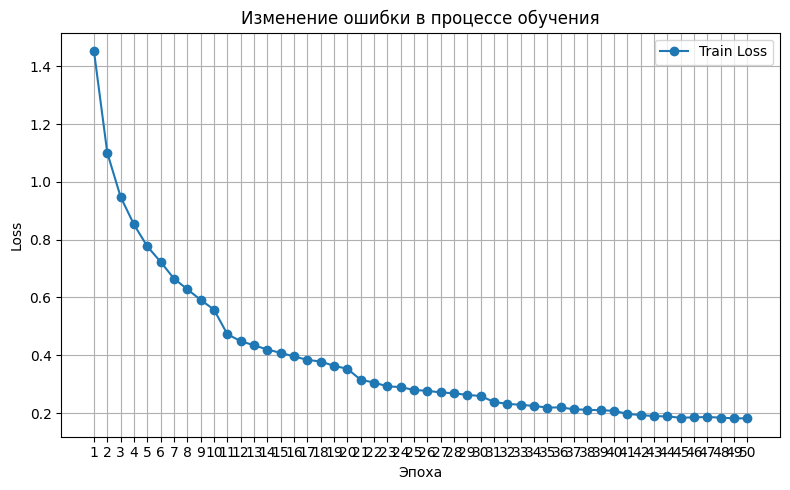

In [18]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o", label="Train Loss")
plt.title("Изменение ошибки в процессе обучения")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.xticks(list(epochs))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 9. Оценка качества на тестовой выборке

После обучения оценим модель на тестовой выборке. Во время оценки отключается вычисление градиентов, а модель переводится в режим `eval()`. Будут рассчитаны средняя ошибка классификации и точность на всём тестовом наборе.

In [19]:
def evaluate_model(model, dataloader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += batch_size

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


test_loss, test_accuracy = evaluate_model(
    model,
    testloader,
    criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Точность на тестовой выборке: {test_accuracy * 100:.2f}%")

Test Loss: 0.3947
Test Accuracy: 0.8751
Точность на тестовой выборке: 87.51%
